# Practical 12 — Model compression and quantization

## Accuracy is not the only deployment metric

We will classify microscopy images from **BloodMNIST** and compare three models with different complexity:

1. a small CNN;
2. a larger CNN;
3. a small pretrained vision model, used here as a compact foundation-model-style baseline.

We will then use pruning, quantization, and knowledge distillation, and compare predictive quality with deployment cost.
$$
\text{Which model gives the best trade-off between quality, memory, and speed?}
$$

## Learning objectives

By the end of the practical, you should be able to:

- measure model size, parameter count, sparsity, and CPU latency;
- distinguish architectural compression from weight compression;
- apply magnitude-based pruning;
- apply post-training INT8 quantization;
- explain knowledge distillation as a compression strategy;
- understand why zeros do not automatically make a model faster;
- compare small, large, and pretrained models;
- select a model for a particular deployment constraint.

In [3]:
import copy
import importlib.metadata as importlib_metadata
import pickle
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import medmnist
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.utils.prune as prune
from medmnist import BloodMNIST, INFO
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.models import MobileNet_V3_Small_Weights

warnings.filterwarnings("ignore")

SEED = 251126
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

print("Python packages:")
for package_name in ["torch", "torchvision", "medmnist", "numpy", "pandas", "scikit-learn"]:
    try:
        print(f"  {package_name}: {importlib_metadata.version(package_name)}")
    except importlib_metadata.PackageNotFoundError:
        print(f"  {package_name}: not found")

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

Python packages:
  torch: 2.14.1
  torchvision: 0.29.1
  medmnist: 3.0.2
  numpy: 2.4.6
  pandas: 2.3.3
  scikit-learn: 1.9.0
Device: cpu
CUDA available: False


# 1. Dataset — BloodMNIST

**BloodMNIST** is an 8-class microscopy-image classification dataset.

It is useful for this practical because:

- training is fast;
- CPU inference is practical;
- it is a real biomedical imaging task;
- compression effects are easy to benchmark.


In [4]:
DATA_FLAG = "bloodmnist"
info = INFO[DATA_FLAG]

print("Task:", info["task"])
print("Channels:", info["n_channels"])
print("Classes:", len(info["label"]))

for k, v in info["label"].items():
    print(f"{k}: {v}")


Task: multi-class
Channels: 3
Classes: 8
0: basophil
1: eosinophil
2: erythroblast
3: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
4: lymphocyte
5: monocyte
6: neutrophil
7: platelet


In [ ]:
# Download the official MedMNIST splits and create DataLoaders.
cnn_transform = transforms.ToTensor()

train_dataset = BloodMNIST(
    split="train",
    transform=cnn_transform,
    download=True,
    size=28,
)
val_dataset = BloodMNIST(
    split="val",
    transform=cnn_transform,
    download=True,
    size=28,
)
test_dataset = BloodMNIST(
    split="test",
    transform=cnn_transform,
    download=True,
    size=28,
)

BATCH_SIZE = 

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 11959
Validation: 1712
Test: 3421


## 2. Exploratory data analysis

Before choosing a model, inspect the data that the model will receive.

For this image dataset we will check:

- split sizes and class balance;
- image shape, data type, and intensity range;
- a sample of pixel-intensity distributions;
- representative images from the training split.

These checks can reveal class imbalance, unexpected image dimensions, or preprocessing problems before training begins.

,train,validation,test
basophil,852,122,244
eosinophil,2181,312,624
erythroblast,1085,155,311
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",2026,290,579
lymphocyte,849,122,243
monocyte,993,143,284
neutrophil,2330,333,666
platelet,1643,235,470


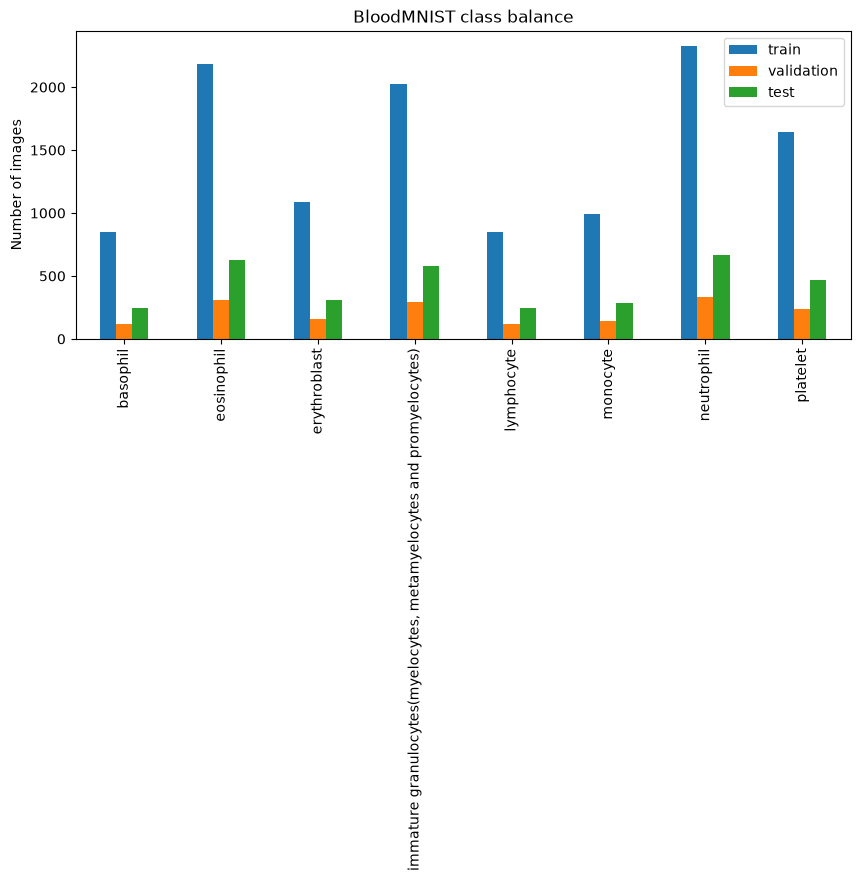

In [6]:
# Check the number of examples in every class and split.
def class_counts(dataset):
    labels = np.asarray(dataset.labels).reshape(-1)
    return pd.Series(labels).value_counts().sort_index()


balance = pd.DataFrame({
    "train": class_counts(train_dataset),
    "validation": class_counts(val_dataset),
    "test": class_counts(test_dataset),
})
balance.index = [info["label"][str(index)] for index in balance.index]
display(balance)

balance.plot(kind="bar", figsize=(10, 4))
plt.ylabel("Number of images")
plt.title("BloodMNIST class balance")
plt.tight_layout()
plt.show()

In [7]:
# Inspect shape, dtype, and intensity range for one transformed image.
example_image, example_label = train_dataset[0]

print("Tensor shape:", tuple(example_image.shape))
print("Tensor dtype:", example_image.dtype)
print("Minimum intensity:", float(example_image.min()))
print("Maximum intensity:", float(example_image.max()))
print("Example class:", info["label"][str(int(example_label[0]))])

Tensor shape: (3, 28, 28)
Tensor dtype: torch.float32
Minimum intensity: 0.12941177189350128
Maximum intensity: 1.0
Example class: platelet


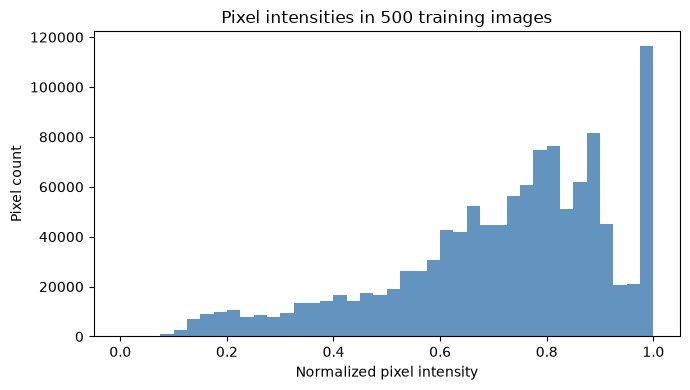

In [8]:
# Plot the intensity distribution for a manageable sample of training images.
sample_size = min(500, len(train_dataset))
pixel_values = []

for index in range(sample_size):
    image, _ = train_dataset[index]
    pixel_values.append(image.numpy().ravel())

pixel_values = np.concatenate(pixel_values)

plt.figure(figsize=(7, 4))
plt.hist(pixel_values, bins=40, color="steelblue", alpha=0.85)
plt.xlabel("Normalized pixel intensity")
plt.ylabel("Pixel count")
plt.title(f"Pixel intensities in {sample_size} training images")
plt.tight_layout()
plt.show()

### Representative images

The images below help us check whether labels, colors, and visual variation look plausible before fitting any model.

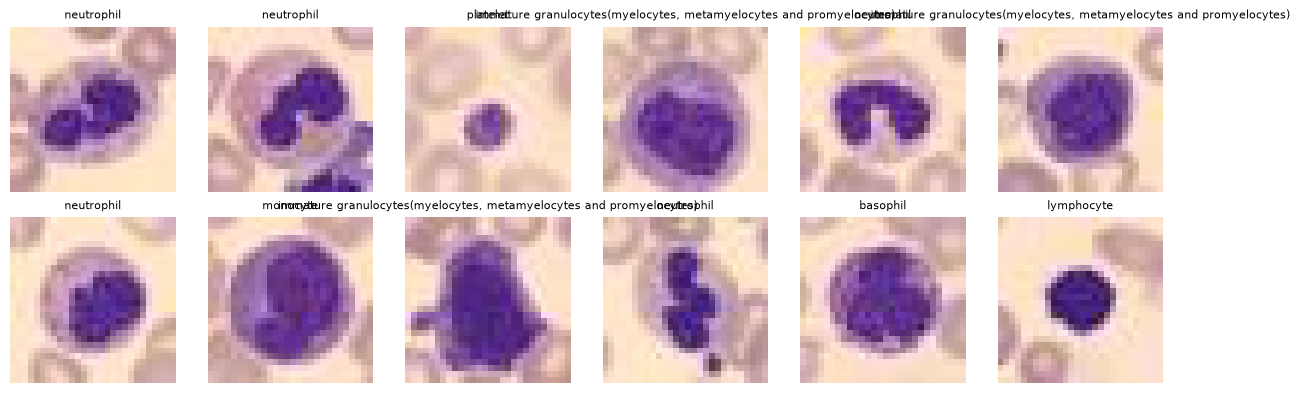

In [9]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))

for ax in axes.ravel():
    idx = np.random.randint(len(train_dataset))
    image, label = train_dataset[idx]
    ax.imshow(np.transpose(image.numpy(), (1, 2, 0)))
    ax.set_title(info["label"][str(int(label[0]))], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 3. Classical ML baseline

A neural network is not the only possible approach. We can flatten a small image representation and fit a conventional classifier.

This is intentionally simple:
$$
\text{image}
\rightarrow
\text{downsampled pixels}
\rightarrow
\text{PCA}
\rightarrow
\text{logistic regression}.
$$
It gives us a useful reference point. If a much larger CNN only improves performance slightly, its extra memory and latency may not be justified.

In [10]:
def dataset_to_pixels(dataset, image_size=14):
    """Convert images to compact, flattened pixel vectors."""
    resize = transforms.Resize((image_size, image_size))
    features, labels = [], []

    for index in range(len(dataset)):
        image, label = dataset[index]
        small_image = resize(image)
        features.append(small_image.flatten().numpy())
        labels.append(int(label[0]))

    return np.asarray(features, dtype=np.float32), np.asarray(labels)


X_train_pixels, y_train_classical = dataset_to_pixels(train_dataset)
X_val_pixels, y_val_classical = dataset_to_pixels(val_dataset)
X_test_pixels, y_test_classical = dataset_to_pixels(test_dataset)

print("Classical ML feature shape:", X_train_pixels.shape)

Classical ML feature shape: (11959, 588)


In [10]:
X_train_pixels

array([[0.9914366 , 0.9114846 , 0.7983894 , ..., 0.6925071 , 0.78571427,
        0.7887956 ],
       [0.9954382 , 0.9963586 , 0.99929976, ..., 0.52296925, 0.53207284,
        0.572389  ],
       [0.7610244 , 0.885014  , 0.98795515, ..., 0.74663866, 0.73284316,
        0.69003606],
       ...,
       [0.96350545, 0.9821429 , 0.9873249 , ..., 0.76582634, 0.6792017 ,
        0.66234505],
       [0.8089636 , 0.89740896, 0.85056025, ..., 0.789986  , 0.80833334,
        0.82657063],
       [0.7618247 , 0.765056  , 0.77801126, ..., 0.7392857 , 0.63256305,
        0.67467   ]], shape=(11959, 588), dtype=float32)

In [11]:
# Standardization and PCA are fitted only on the training split.
classical_model = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=50, svd_solver="randomized", random_state=SEED)),
    ("logistic", LogisticRegression(max_iter=500, n_jobs=-1)),
])

classical_model.fit(X_train_pixels, y_train_classical)
classical_predictions = classical_model.predict(X_test_pixels)

simple_ml_results = pd.DataFrame([{
    "model": "PCA + LogisticRegression",
    "accuracy": accuracy_score(y_test_classical, classical_predictions),
    "macro_f1": f1_score(
        y_test_classical,
        classical_predictions,
        average="macro",
    ),
}])

display(simple_ml_results.round(4))

,model,accuracy,macro_f1
0,PCA + LogisticRegression,0.7445,0.7156


In [15]:
# Estimate storage and prediction latency for the classical baseline.
classical_size_mb = len(pickle.dumps(classical_model)) / (1024 ** 2)
probe = X_test_pixels[:1]

timings = []
for _ in range(100):
    start = time.perf_counter()
    classical_model.predict(probe)
    timings.append((time.perf_counter() - start) * 1000)

simple_ml_results["size_mb"] = classical_size_mb
simple_ml_results["latency_ms"] = float(np.median(timings))
simple_ml_results["throughput_samples_s"] = 1000 / simple_ml_results["latency_ms"]

display(simple_ml_results.round(4))

,model,accuracy,macro_f1,size_mb,latency_ms,throughput_samples_s
0,PCA + LogisticRegression,0.7445,0.7156,0.1316,0.6103,1638.6726


## 4. Three neural model sizes

We now compare neural models with different complexity:

- **SmallCNN:** a compact architecture with fewer channels and layers;
- **LargeCNN:** a wider/deeper source model for compression;
- **SmallFM:** a compact pretrained MobileNetV3-Small model.

The comparison is not only about accuracy. A model must also fit the available memory and latency budget.

For an FP32 model with $N$ stored parameters:
$$
M_{\mathrm{weights}} \approx 4N \ \text{bytes}.
$$

In [16]:
class SmallCNN(nn.Module):
    """A compact CNN with two convolutional blocks."""

    def __init__(self, num_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

### Large CNN

The large CNN has more channels and more convolutional blocks. It is used as the source model for pruning and as the teacher for knowledge distillation.

In [17]:
class LargeCNN(nn.Module):
    """A wider and deeper CNN used as the compression source model."""

    def __init__(self, num_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [18]:
def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())


small_model = SmallCNN().to(DEVICE)
large_model = LargeCNN().to(DEVICE)
baseline_model = large_model

display(pd.DataFrame([
    {"model": "SmallCNN", "parameters": count_parameters(small_model)},
    {"model": "LargeCNN", "parameters": count_parameters(large_model)},
]))

,model,parameters
0,SmallCNN,5352
1,LargeCNN,157608


The parameter table gives a first complexity comparison before training.

## 5. Shared training utilities

The same training and evaluation functions are reused for every neural model. This keeps the comparison fair: the data split and metrics stay fixed while the model changes.

In [19]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    """Run one optimization pass over the training data."""
    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)

### Prediction and evaluation

Training changes the parameters. Evaluation only measures predictions, so it is wrapped in no-gradient mode and does not update the model.

In [20]:
@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    true_labels, predicted_labels = [], []

    for images, labels in loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu().numpy()
        true_labels.extend(labels.squeeze(1).numpy())
        predicted_labels.extend(predictions)

    return np.asarray(true_labels), np.asarray(predicted_labels)


def evaluate(model, loader, device):
    y_true, y_pred = predict(model, loader, device)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

In [21]:
def fit_model(
    model,
    train_data,
    validation_data,
    epochs=30,
    learning_rate=1e-3,
    patience=5,
    min_delta=1e-3,
):
    """Train up to epochs and restore the best validation checkpoint."""
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()
    history = []

    best_score = -np.inf
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(
            model,
            train_data,
            optimizer,
            criterion,
            DEVICE,
        )
        metrics = evaluate(model, validation_data, DEVICE)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            **metrics,
        })

        score = metrics["macro_f1"]
        improved = score > best_score + min_delta

        if improved:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:02d} | "
            f"loss={train_loss:.4f} | "
            f"val_acc={metrics['accuracy']:.4f} | "
            f"val_f1={metrics['macro_f1']:.4f}"
        )

        if epochs_without_improvement >= patience:
            print(f"Early stopping after {epoch} epochs.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"Restored best validation macro-F1: {best_score:.4f}")

    return model, pd.DataFrame(history)

### Training schedule and early stopping

Each neural model is allowed up to **30 epochs**. We monitor validation macro-F1 after every epoch.

Training stops when the score has not improved for five consecutive epochs, and the best validation checkpoint is restored. Therefore, 30 is a maximum budget rather than a requirement to run all epochs.

In [22]:
# Train the larger CNN first; it will also act as the teacher for distillation.
baseline_model, history = fit_model(
    baseline_model, train_loader, val_loader, epochs=30, patience=5
)
large_model = baseline_model

Epoch 01 | loss=0.7582 | val_acc=0.6180 | val_f1=0.5528
Epoch 02 | loss=0.3345 | val_acc=0.6419 | val_f1=0.5422
Epoch 03 | loss=0.2466 | val_acc=0.8178 | val_f1=0.7818
Epoch 04 | loss=0.2143 | val_acc=0.5818 | val_f1=0.4441
Epoch 05 | loss=0.1759 | val_acc=0.6530 | val_f1=0.5601
Epoch 06 | loss=0.1532 | val_acc=0.8890 | val_f1=0.8727
Epoch 07 | loss=0.1556 | val_acc=0.7850 | val_f1=0.7452
Epoch 08 | loss=0.1389 | val_acc=0.8528 | val_f1=0.8375
Epoch 09 | loss=0.1224 | val_acc=0.8405 | val_f1=0.8234
Epoch 10 | loss=0.1009 | val_acc=0.8616 | val_f1=0.8526
Epoch 11 | loss=0.1080 | val_acc=0.8505 | val_f1=0.8466
Early stopping after 11 epochs.
Restored best validation macro-F1: 0.8727


In [24]:
# Train the small CNN separately.
small_model, small_history = fit_model(
    small_model, train_loader, val_loader, epochs=30
)

Epoch 01 | loss=0.8473 | val_acc=0.7039 | val_f1=0.5904
Epoch 02 | loss=0.8352 | val_acc=0.7237 | val_f1=0.6249
Epoch 03 | loss=0.8212 | val_acc=0.7021 | val_f1=0.5816
Epoch 04 | loss=0.8119 | val_acc=0.7249 | val_f1=0.6060
Epoch 05 | loss=0.7974 | val_acc=0.7371 | val_f1=0.6491
Epoch 06 | loss=0.7866 | val_acc=0.7249 | val_f1=0.6161
Epoch 07 | loss=0.7769 | val_acc=0.6998 | val_f1=0.6073
Epoch 08 | loss=0.7704 | val_acc=0.7371 | val_f1=0.6340
Epoch 09 | loss=0.7559 | val_acc=0.7500 | val_f1=0.6531
Epoch 10 | loss=0.7439 | val_acc=0.7459 | val_f1=0.6630
Epoch 11 | loss=0.7392 | val_acc=0.7301 | val_f1=0.6354
Epoch 12 | loss=0.7268 | val_acc=0.7582 | val_f1=0.6651
Epoch 13 | loss=0.7185 | val_acc=0.7739 | val_f1=0.6995
Epoch 14 | loss=0.7112 | val_acc=0.7436 | val_f1=0.6566
Epoch 15 | loss=0.7031 | val_acc=0.7593 | val_f1=0.6701
Epoch 16 | loss=0.6988 | val_acc=0.7728 | val_f1=0.7021
Epoch 17 | loss=0.6946 | val_acc=0.7658 | val_f1=0.6845
Epoch 18 | loss=0.6844 | val_acc=0.7880 | val_f1

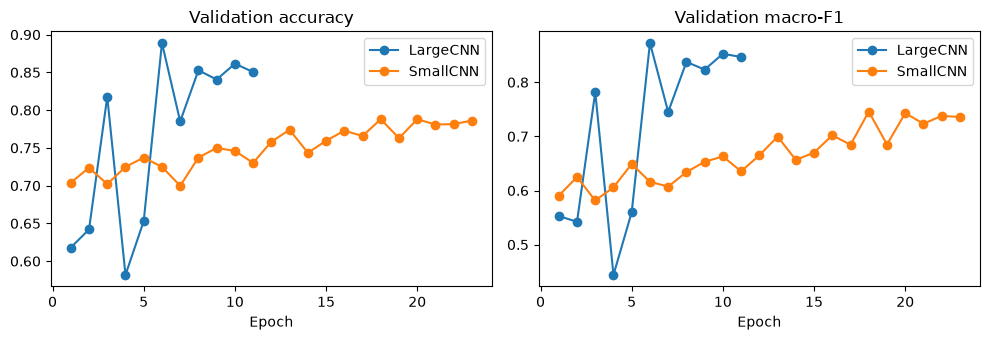

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for history_frame, name in [(history, "LargeCNN"), (small_history, "SmallCNN")]:
    axes[0].plot(history_frame["epoch"], history_frame["accuracy"], marker="o", label=name)
    axes[1].plot(history_frame["epoch"], history_frame["macro_f1"], marker="o", label=name)

axes[0].set_title("Validation accuracy")
axes[1].set_title("Validation macro-F1")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Small pretrained vision model

MobileNetV3-Small is a compact pretrained vision model. It is not biology-specific, but it illustrates the deployment pattern:
$$
\text{pretrained representation} \longrightarrow \text{small task-specific head}.
$$
We freeze its feature extractor and train only the final classifier.

In [26]:
fm_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224)),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])

fm_train_dataset = BloodMNIST(split="train", transform=fm_transform, download=True, size=28)
fm_val_dataset = BloodMNIST(split="val", transform=fm_transform, download=True, size=28)
fm_test_dataset = BloodMNIST(split="test", transform=fm_transform, download=True, size=28)

fm_train_loader = DataLoader(fm_train_dataset, batch_size=64, shuffle=True, num_workers=0)
fm_val_loader = DataLoader(fm_val_dataset, batch_size=64, shuffle=False, num_workers=0)
fm_test_loader = DataLoader(fm_test_dataset, batch_size=64, shuffle=False, num_workers=0)

In [27]:
class SmallFM(nn.Module):
    def __init__(self, num_classes=8, pretrained=True):
        super().__init__()
        weights = MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
        self.backbone = models.mobilenet_v3_small(weights=weights)

        for parameter in self.backbone.features.parameters():
            parameter.requires_grad = False

        input_features = self.backbone.classifier[-1].in_features
        self.backbone.classifier[-1] = nn.Linear(input_features, num_classes)

    def forward(self, images):
        return self.backbone(images)


try:
    small_fm = SmallFM(pretrained=True).to(DEVICE)
except Exception as error:
    print("Pretrained weights were unavailable; using the architecture without them.")
    print(type(error).__name__, error)
    small_fm = SmallFM(pretrained=False).to(DEVICE)

small_fm, fm_history = fit_model(
    small_fm, fm_train_loader, fm_val_loader, epochs=30, patience=5, learning_rate=1e-3
)

Epoch 01 | loss=0.6288 | val_acc=0.6554 | val_f1=0.5180
Epoch 02 | loss=0.4016 | val_acc=0.6764 | val_f1=0.5724
Epoch 03 | loss=0.3441 | val_acc=0.8090 | val_f1=0.7667
Epoch 04 | loss=0.3103 | val_acc=0.8768 | val_f1=0.8599
Epoch 05 | loss=0.2761 | val_acc=0.8972 | val_f1=0.8869
Epoch 06 | loss=0.2531 | val_acc=0.8838 | val_f1=0.8670
Epoch 07 | loss=0.2391 | val_acc=0.9071 | val_f1=0.8944
Epoch 08 | loss=0.2138 | val_acc=0.8914 | val_f1=0.8764
Epoch 09 | loss=0.1927 | val_acc=0.8972 | val_f1=0.8833
Epoch 10 | loss=0.1736 | val_acc=0.8989 | val_f1=0.8822
Epoch 11 | loss=0.1701 | val_acc=0.8960 | val_f1=0.8839
Epoch 12 | loss=0.1484 | val_acc=0.8914 | val_f1=0.8757
Early stopping after 12 epochs.
Restored best validation macro-F1: 0.8944


## 5. Knowledge distillation

Knowledge distillation trains a small student to imitate a larger teacher. The student receives both hard class labels and the teacher's softer probability distribution.
$$
\mathcal{L}
=
(1-\alpha)\mathcal{L}_{CE}
+
\alpha T^2\mathcal{L}_{KL}.
$$
The temperature $T$ reveals similarities between classes. This can transfer useful structure from the large model without copying its parameter count.

In [28]:
def distill_student(
    teacher,
    student,
    train_data,
    validation_data,
    max_epochs=30,
    alpha=0.5,
    temperature=3.0,
    patience=5,
):
    teacher = teacher.to(DEVICE).eval()
    student = student.to(DEVICE).train()
    optimizer = torch.optim.Adam(student.parameters(), lr=1e-3)
    hard_loss = nn.CrossEntropyLoss()

    best_score = -np.inf
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        student.train()

        for images, labels in train_data:
            images = images.to(DEVICE)
            labels = labels.squeeze(1).long().to(DEVICE)

            with torch.no_grad():
                teacher_logits = teacher(images)

            student_logits = student(images)
            loss_hard = hard_loss(student_logits, labels)
            loss_soft = F.kl_div(
                F.log_softmax(student_logits / temperature, dim=1),
                F.softmax(teacher_logits / temperature, dim=1),
                reduction="batchmean",
            ) * temperature ** 2
            loss = (1 - alpha) * loss_hard + alpha * loss_soft

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        validation_metrics = evaluate(student, validation_data, DEVICE)
        score = validation_metrics["macro_f1"]
        improved = score > best_score + 1e-3

        if improved:
            best_score = score
            best_state = copy.deepcopy(student.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Distillation epoch {epoch:02d} | "
            f"loss={loss.item():.4f} | "
            f"val_f1={score:.4f}"
        )

        if epochs_without_improvement >= patience:
            print(f"Distillation early stopping after {epoch} epochs.")
            break

    if best_state is not None:
        student.load_state_dict(best_state)

    return student.cpu()

In [31]:
distilled_student = distill_student(
    teacher=large_model,
    student=SmallCNN(),
    train_data=train_loader,
    validation_data=val_loader,
    max_epochs=60,
    patience=5)

Distillation epoch 01 | loss=5.6812 | val_f1=0.0407
Distillation epoch 02 | loss=5.4814 | val_f1=0.0776
Distillation epoch 03 | loss=5.0100 | val_f1=0.2090
Distillation epoch 04 | loss=4.5530 | val_f1=0.2665
Distillation epoch 05 | loss=4.3930 | val_f1=0.2581
Distillation epoch 06 | loss=3.9052 | val_f1=0.2386
Distillation epoch 07 | loss=4.1488 | val_f1=0.2917
Distillation epoch 08 | loss=3.7358 | val_f1=0.3018
Distillation epoch 09 | loss=4.2769 | val_f1=0.2948
Distillation epoch 10 | loss=3.3479 | val_f1=0.3524
Distillation epoch 11 | loss=3.7670 | val_f1=0.3038
Distillation epoch 12 | loss=4.2379 | val_f1=0.3388
Distillation epoch 13 | loss=4.1436 | val_f1=0.3781
Distillation epoch 14 | loss=3.8783 | val_f1=0.3249
Distillation epoch 15 | loss=3.6342 | val_f1=0.3368
Distillation epoch 16 | loss=3.2293 | val_f1=0.4256
Distillation epoch 17 | loss=3.3527 | val_f1=0.4123
Distillation epoch 18 | loss=3.3665 | val_f1=0.4176
Distillation epoch 19 | loss=3.1394 | val_f1=0.4020
Distillation

## 6. Deployment benchmark

We measure quality, parameter count, non-zero parameters, serialized size, CPU latency, and throughput.

Timing is performed on CPU so that the comparison is reproducible across machines.

In [32]:
ARTIFACT_DIR = Path("compression_models")
ARTIFACT_DIR.mkdir(exist_ok=True)


def count_nonzero_parameters(model):
    total = 0
    nonzero = 0
    for parameter in model.parameters():
        total += parameter.numel()
        nonzero += torch.count_nonzero(parameter.detach()).item()
    return nonzero, total


def serialized_size_mb(model, filename):
    path = ARTIFACT_DIR / filename
    torch.save(model.state_dict(), path)
    return path.stat().st_size / (1024 ** 2)


@torch.no_grad()
def benchmark_latency(model, input_shape, warmup=20, repetitions=100):
    model = model.cpu().eval()
    dummy = torch.randn(*input_shape)

    for _ in range(warmup):
        model(dummy)

    timings = []
    for _ in range(repetitions):
        start = time.perf_counter()
        model(dummy)
        timings.append((time.perf_counter() - start) * 1000)

    timings = np.asarray(timings)
    median = float(np.median(timings))
    return {
        "latency_ms": median,
        "latency_p95_ms": float(np.percentile(timings, 95)),
        "throughput_samples_s": float(1000 / median),
    }


def benchmark_model(model, name, loader, input_shape):
    model = model.cpu().eval()
    quality = evaluate(model, loader, torch.device("cpu"))
    nonzero, total = count_nonzero_parameters(model)
    return {
        "model": name,
        **quality,
        "params": total,
        "nonzero_params": nonzero,
        "sparsity": 1 - nonzero / total if total else 0.0,
        "size_mb": serialized_size_mb(model, f"{name}.pt"),
        **benchmark_latency(model, input_shape),
    }

In [33]:
results = []

results.append(benchmark_model(
    copy.deepcopy(small_model), "SmallCNN_FP32", test_loader, (1, 3, 28, 28)
))
results.append(benchmark_model(
    copy.deepcopy(large_model), "LargeCNN_FP32", test_loader, (1, 3, 28, 28)
))
results.append(benchmark_model(
    copy.deepcopy(small_fm), "SmallFM_FP32", fm_test_loader, (1, 3, 224, 224)
))
results.append(benchmark_model(
    copy.deepcopy(distilled_student), "SmallCNN_KD", test_loader, (1, 3, 28, 28)
))

# Keep this alias because later compression cells operate on the large CNN.
baseline_cpu = copy.deepcopy(large_model).cpu()

pd.DataFrame(results).round(4)

,model,accuracy,macro_f1,params,nonzero_params,sparsity,size_mb,latency_ms,latency_p95_ms,throughput_samples_s
0,SmallCNN_FP32,0.7723,0.7259,5352,5352,0.0,0.0235,0.2770,2.7488,3610.1081
1,LargeCNN_FP32,0.8807,0.8667,157608,157608,0.0,0.6161,1.3068,1.8763,765.1988
2,SmallFM_FP32,0.9000,0.8833,1526056,1526056,0.0,5.9509,9.2519,10.9997,108.0853
3,SmallCNN_KD,0.7080,0.5872,5352,5352,0.0,0.0235,0.2345,0.3195,4263.4836


## 7. Unstructured magnitude pruning

Magnitude pruning removes weights with small absolute values:
$$
|w_i|<\tau \Rightarrow w_i=0
$$
We will test:
$$
20\%,\;40\%,\;60\%,\;80\%,\;90\%
$$
### Important

Unstructured pruning creates zero weights but does **not** change tensor dimensions.

Therefore:
$$
\text{sparsity} \neq \text{automatic speedup}
$$


In [34]:
def apply_global_pruning(model, amount):
    model = copy.deepcopy(model).cpu()

    targets = []
    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            targets.append((module, "weight"))

    prune.global_unstructured(
        targets,
        pruning_method=prune.L1Unstructured,
        amount=amount
    )

    for module, name in targets:
        prune.remove(module, name)

    return model


In [35]:
PRUNING_LEVELS = [0.20, 0.40, 0.60, 0.80, 0.90]
pruned_models = {}

for amount in PRUNING_LEVELS:
    model = apply_global_pruning(baseline_cpu, amount)
    pruned_models[amount] = model

    results.append(
        benchmark_model(
            model,
            f"LargeCNN_Pruned_{int(amount * 100)}",
            test_loader,
            (1, 3, 28, 28),
        )
    )

pd.DataFrame(results).tail(len(PRUNING_LEVELS)).round(4)

,model,accuracy,macro_f1,params,nonzero_params,sparsity,size_mb,latency_ms,latency_p95_ms,throughput_samples_s
4,LargeCNN_Pruned_20,0.8799,0.8611,157608,126306,0.1986,0.6164,1.4401,2.6717,694.3962
5,LargeCNN_Pruned_40,0.8123,0.7252,157608,95003,0.3972,0.6164,1.5655,4.3129,638.7736
6,LargeCNN_Pruned_60,0.5019,0.3567,157608,63701,0.5958,0.6164,1.1567,1.9564,864.5284
7,LargeCNN_Pruned_80,0.2309,0.1055,157608,32398,0.7944,0.6164,1.2056,1.7694,829.4281
8,LargeCNN_Pruned_90,0.1824,0.0386,157608,16747,0.8937,0.6164,1.2232,2.2046,817.5278


## Structured channel pruning

Unstructured pruning sets individual weights to zero. Structured pruning removes whole output channels from convolutional layers.

Here we use an L2-norm criterion:
$$
\|W_{c,:,:,:}\|_2
$$
Channels with the smallest norm are pruned. The tensor shapes are kept unchanged in this classroom implementation, so we can observe an important limitation:
$$
\text{structured sparsity} \neq \text{automatic size reduction}.
$$
To obtain a smaller and faster dense model, the surviving channels must be used to rebuild the network.

In [36]:
def apply_structured_pruning(model, amount=0.25):
    """Zero complete convolutional output channels by L2 norm."""
    structured_model = copy.deepcopy(model).cpu()

    for module in structured_model.modules():
        if isinstance(module, nn.Conv2d):
            prune.ln_structured(
                module,
                name="weight",
                amount=amount,
                n=2,
                dim=0,
            )
            prune.remove(module, "weight")

    return structured_model


structured_model = apply_structured_pruning(baseline_cpu, amount=0.25)

results.append(benchmark_model(
    structured_model,
    "LargeCNN_StructuredPruned_25",
    test_loader,
    (1, 3, 28, 28),
))

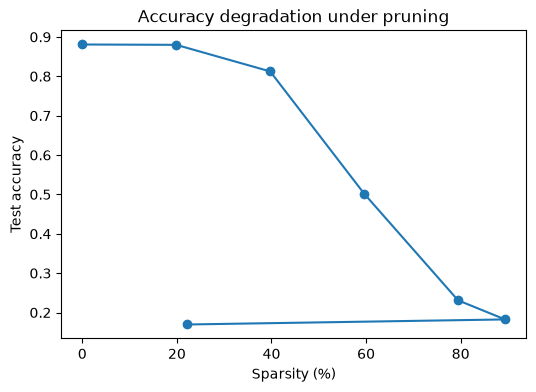

In [38]:
pruning_df = pd.DataFrame(results)
pruning_df = pruning_df[pruning_df["model"].str.contains("Pruned|LargeCNN")]

plt.figure(figsize=(6,4))
plt.plot(pruning_df["sparsity"]*100, pruning_df["accuracy"], marker="o")
plt.xlabel("Sparsity (%)")
plt.ylabel("Test accuracy")
plt.title("Accuracy degradation under pruning")
plt.show()


## 8. Fine-tuning after pruning

Compression often works better as:
$$
\text{Train} \rightarrow \text{Compress} \rightarrow \text{Fine-tune}
$$
We will fine-tune selected pruned models.


In [39]:
def finetune(
    model,
    train_data,
    validation_data,
    max_epochs=30,
    lr=3e-4,
    patience=5,
):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    best_score = -np.inf
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        loss = train_one_epoch(model, train_data, optimizer, criterion, DEVICE)
        metrics = evaluate(model, validation_data, DEVICE)
        score = metrics["macro_f1"]

        if score > best_score + 1e-3:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Fine-tune {epoch:02d} | "
            f"loss={loss:.4f} | "
            f"val_acc={metrics['accuracy']:.4f} | "
            f"val_f1={score:.4f}"
        )

        if epochs_without_improvement >= patience:
            print(f"Fine-tuning early stopping after {epoch} epochs.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model.cpu()

In [40]:
finetuned_models = {}

for amount in [0.60, 0.80]:
    print(f"Fine-tuning {int(amount * 100)}% pruned model")

    model = finetune(copy.deepcopy(pruned_models[amount]), train_loader, val_loader, max_epochs=30, patience=5)
    finetuned_models[amount] = model

    results.append(
        benchmark_model(
            model,
            f"LargeCNN_Pruned_{int(amount * 100)}_FT",
            test_loader,
            (1, 3, 28, 28),
        )
    )

Fine-tuning 60% pruned model
Fine-tune 01 | loss=0.1179 | val_acc=0.8797 | val_f1=0.8535
Fine-tune 02 | loss=0.1017 | val_acc=0.9504 | val_f1=0.9441
Fine-tune 03 | loss=0.0929 | val_acc=0.9393 | val_f1=0.9354
Fine-tune 04 | loss=0.0832 | val_acc=0.9439 | val_f1=0.9359
Fine-tune 05 | loss=0.0739 | val_acc=0.9480 | val_f1=0.9418
Fine-tune 06 | loss=0.0687 | val_acc=0.9428 | val_f1=0.9369
Fine-tune 07 | loss=0.0607 | val_acc=0.9147 | val_f1=0.8977
Fine-tuning early stopping after 7 epochs.
Fine-tuning 80% pruned model
Fine-tune 01 | loss=0.1496 | val_acc=0.9363 | val_f1=0.9266
Fine-tune 02 | loss=0.1230 | val_acc=0.8429 | val_f1=0.8331
Fine-tune 03 | loss=0.1037 | val_acc=0.9287 | val_f1=0.9183
Fine-tune 04 | loss=0.0924 | val_acc=0.9457 | val_f1=0.9374
Fine-tune 05 | loss=0.0880 | val_acc=0.9311 | val_f1=0.9219
Fine-tune 06 | loss=0.0744 | val_acc=0.9445 | val_f1=0.9343
Fine-tune 07 | loss=0.0680 | val_acc=0.9322 | val_f1=0.9188
Fine-tune 08 | loss=0.0740 | val_acc=0.9287 | val_f1=0.9223

## 9. Architectural compression

Compression does not always require a special algorithm.

Sometimes the simplest strategy is to use a smaller model.

Unlike unstructured pruning, this changes tensor dimensions and therefore tends to reduce actual compute more directly.


In [34]:
# The trained SmallCNN is already an architectural-compression baseline.
# It has fewer layers and channels than LargeCNN, so its tensor shapes are smaller.
small_model_cpu = copy.deepcopy(small_model).cpu()
display(pd.DataFrame([
    {"model": "SmallCNN", "parameters": count_parameters(small_model_cpu)},
    {"model": "LargeCNN", "parameters": count_parameters(baseline_cpu)},
]))

,model,parameters
0,SmallCNN,5352
1,LargeCNN,157608


## 10. Post-training dynamic INT8 quantization

Conceptually:
$$
FP32 \rightarrow INT8
$$
For a classroom-friendly implementation, we will use **dynamic INT8 quantization** on the `Linear` layers.

This is deliberately conservative for a CNN: the convolutional layers remain floating point.

It still demonstrates the central idea that reducing numerical precision can reduce model size and change inference performance.


In [41]:
def dynamic_int8_quantize(model):
    return torch.ao.quantization.quantize_dynamic(
        copy.deepcopy(model).cpu().eval(),
        {nn.Linear},
        dtype=torch.qint8,
    )


small_int8 = dynamic_int8_quantize(small_model)
large_int8 = dynamic_int8_quantize(large_model)

results.append(benchmark_model(
    small_int8, "SmallCNN_INT8_dynamic", test_loader, (1, 3, 28, 28)
))
results.append(benchmark_model(
    large_int8, "LargeCNN_INT8_dynamic", test_loader, (1, 3, 28, 28)
))

In [42]:
results

[{'model': 'SmallCNN_FP32',
  'accuracy': 0.7722888044431453,
  'macro_f1': 0.7259023670702327,
  'params': 5352,
  'nonzero_params': 5352,
  'sparsity': 0.0,
  'size_mb': 0.02352619171142578,
  'latency_ms': 0.2770000137388706,
  'latency_p95_ms': 2.7488100255140986,
  'throughput_samples_s': 3610.1081241920274},
 {'model': 'LargeCNN_FP32',
  'accuracy': 0.8807366267173341,
  'macro_f1': 0.8666771246811771,
  'params': 157608,
  'nonzero_params': 157608,
  'sparsity': 0.0,
  'size_mb': 0.6161460876464844,
  'latency_ms': 1.3068499974906445,
  'latency_p95_ms': 1.8762699677608907,
  'throughput_samples_s': 765.198761847309},
 {'model': 'SmallFM_FP32',
  'accuracy': 0.9000292312189418,
  'macro_f1': 0.8833439780607673,
  'params': 1526056,
  'nonzero_params': 1526056,
  'sparsity': 0.0,
  'size_mb': 5.950921058654785,
  'latency_ms': 9.2519499885384,
  'latency_p95_ms': 10.999724979046732,
  'throughput_samples_s': 108.08532268752326},
 {'model': 'SmallCNN_KD',
  'accuracy': 0.707980122

## Low-rank factorization

A dense linear layer computes:
$$
y = Wx + b.
$$
If $W$ is approximately low rank, we can replace it with two smaller matrices:
$$
W \approx W_2 W_1,
$$
where $W_1$ maps the input to a lower-dimensional representation and $W_2$ maps it back to the original output dimension.

We initialize the factors with a truncated singular value decomposition (SVD), then fine-tune the factorized model.

In [43]:
def factorize_large_classifier(model, rank=32):
    """Replace the 128 x 128 classifier matrix with two low-rank matrices."""
    factorized = copy.deepcopy(model).cpu()

    original_first = factorized.classifier[1]
    original_last = factorized.classifier[3]

    left, singular_values, right_transpose = torch.linalg.svd(
        original_first.weight.detach(),
        full_matrices=False,
    )

    first_factor = nn.Linear(
        original_first.in_features,
        rank,
        bias=False,
    )
    second_factor = nn.Linear(
        rank,
        original_first.out_features,
        bias=True,
    )

    with torch.no_grad():
        first_factor.weight.copy_(
            singular_values[:rank, None] * right_transpose[:rank, :]
        )
        second_factor.weight.copy_(left[:, :rank])
        second_factor.bias.copy_(original_first.bias)

    factorized.classifier = nn.Sequential(
        nn.Flatten(),
        first_factor,
        second_factor,
        nn.ReLU(inplace=True),
        copy.deepcopy(original_last),
    )
    return factorized


low_rank_model = factorize_large_classifier(baseline_cpu, rank=32)

results.append(benchmark_model(
    low_rank_model,
    "LargeCNN_LowRank32",
    test_loader,
    (1, 3, 28, 28),
))

In [44]:
# Fine-tuning can recover some accuracy lost by the low-rank approximation.
low_rank_finetuned = finetune(
    copy.deepcopy(low_rank_model),
    train_loader,
    val_loader,
    max_epochs=30,
    patience=5,
    lr=3e-4,
)

results.append(benchmark_model(
    low_rank_finetuned,
    "LargeCNN_LowRank32_FT",
    test_loader,
    (1, 3, 28, 28),
))

Fine-tune 01 | loss=0.1097 | val_acc=0.9287 | val_f1=0.9165
Fine-tune 02 | loss=0.0923 | val_acc=0.9106 | val_f1=0.9002
Fine-tune 03 | loss=0.0877 | val_acc=0.9433 | val_f1=0.9355
Fine-tune 04 | loss=0.0786 | val_acc=0.9369 | val_f1=0.9302
Fine-tune 05 | loss=0.0763 | val_acc=0.9270 | val_f1=0.9195
Fine-tune 06 | loss=0.0668 | val_acc=0.9393 | val_f1=0.9296
Fine-tune 07 | loss=0.0588 | val_acc=0.9206 | val_f1=0.9049
Fine-tune 08 | loss=0.0546 | val_acc=0.9579 | val_f1=0.9535
Fine-tune 09 | loss=0.0446 | val_acc=0.8972 | val_f1=0.8784
Fine-tune 10 | loss=0.0477 | val_acc=0.9112 | val_f1=0.8841
Fine-tune 11 | loss=0.0452 | val_acc=0.9416 | val_f1=0.9302
Fine-tune 12 | loss=0.0391 | val_acc=0.9445 | val_f1=0.9386
Fine-tune 13 | loss=0.0398 | val_acc=0.9387 | val_f1=0.9331
Fine-tuning early stopping after 13 epochs.


## What does dynamic quantization do?

For dynamically quantized layers:

- weights are stored in INT8;
- activations are quantized during inference.

For CNN-heavy architectures, full static quantization can provide larger benefits because convolutional activations can also be quantized.

### Optional advanced extension

Implement full static / PT2E / TorchAO quantization and compare it with dynamic quantization.


## Other compression methods

The practical demonstrates pruning, quantization, and knowledge distillation. Other useful methods include:

| Method | Main idea | Potential benefit | Main caveat |
|---|---|---|---|
| Structured pruning | Remove complete channels, filters, or blocks | Can reduce dense computation | Usually requires rebuilding the network |
| Low-rank factorization | Replace one large matrix with two smaller matrices | Fewer parameters and operations | Approximation can reduce accuracy |
| Weight sharing | Store groups of similar weights using shared centroids | Smaller storage | Requires compatible runtime support |
| Operator fusion | Combine operations such as convolution, batch normalization, and activation | Lower memory traffic and latency | Backend-dependent |
| Mixed precision | Use FP16, BF16, INT8, or lower precision selectively | Lower memory and faster inference | Some layers are more sensitive than others |
| Knowledge distillation | Train a small student from a larger teacher | Transfers useful behavior to a compact model | Requires a teacher and additional training |

Structured pruning and low-rank factorization are implemented in the next cells; static quantization remains an optional extension.

In [45]:
for amount in [0.60, 0.80]:
    combined = dynamic_int8_quantize(pruned_models[amount])

    results.append(
        benchmark_model(
            combined,
            f"LargeCNN_Pruned_{int(amount * 100)}_INT8",
            test_loader,
            (1, 3, 28, 28),
        )
    )

## Consolidate benchmark results

Before calculating compression ratios and Pareto metrics, collect all neural-model benchmark records into one dataframe.

In [46]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["accuracy", "size_mb"],
    ascending=[False, True]
).reset_index(drop=True)



## 14. Relative compression metrics

### Compression ratio
$$
CR=\frac{Size_{baseline}}{Size_{compressed}}
$$
### Accuracy retention
$$
A_R=\frac{Accuracy_{compressed}}{Accuracy_{baseline}}
$$
### Speedup
$$
S=\frac{Latency_{baseline}}{Latency_{compressed}}
$$
### Parameter reduction
$$
R_p=1-\frac{N_{compressed}}{N_{baseline}}
$$


In [47]:
baseline = results_df.loc[
    results_df["model"] == "LargeCNN_FP32"
].iloc[0]

results_df["compression_ratio"] = baseline["size_mb"] / results_df["size_mb"]
results_df["accuracy_retention"] = results_df["accuracy"] / baseline["accuracy"]
results_df["speedup"] = baseline["latency_ms"] / results_df["latency_ms"]
results_df["parameter_reduction"] = 1 - results_df["params"] / baseline["params"]

display_cols = [
    "model", "accuracy", "macro_f1",
    "params", "sparsity", "size_mb",
    "latency_ms", "throughput_samples_s",
    "compression_ratio", "accuracy_retention",
    "speedup", "parameter_reduction"
]

# The metrics are retained for the final deployment score.

In [48]:
results_df

,model,accuracy,macro_f1,params,nonzero_params,sparsity,size_mb,latency_ms,latency_p95_ms,throughput_samples_s,compression_ratio,accuracy_retention,speedup,parameter_reduction
0,LargeCNN_LowRank32_FT,0.949138,0.941439,149416,149416,0.000000,0.585555,1.44315,2.739760,692.928669,1.052243,1.077663,0.905554,0.051977
1,LargeCNN_Pruned_80_FT,0.945630,0.942879,157608,156809,0.005070,0.616489,1.43850,3.742305,695.168573,0.999443,1.073681,0.908481,0.000000
2,LargeCNN_Pruned_60_FT,0.937738,0.927837,157608,156962,0.004099,0.616489,1.40265,2.954760,712.936213,0.999443,1.064720,0.931701,0.000000
3,SmallFM_FP32,0.900029,0.883344,1526056,1526056,0.000000,5.950921,9.25195,10.999725,108.085323,0.103538,1.021905,0.141251,-8.682605
4,LargeCNN_LowRank32,0.881321,0.867290,149416,149416,0.000000,0.585423,1.39610,2.345580,716.281065,1.052479,1.000664,0.936072,0.051977
5,LargeCNN_FP32,0.880737,0.866677,157608,157608,0.000000,0.616146,1.30685,1.876270,765.198762,1.000000,1.000000,1.000000,0.000000
6,LargeCNN_INT8_dynamic,0.880152,0.865389,140064,140064,0.000000,0.568192,1.44515,2.287805,691.969690,1.084399,0.999336,0.904301,0.111314
7,LargeCNN_Pruned_20,0.879860,0.861093,157608,126306,0.198607,0.616361,1.44010,2.671665,694.396226,0.999652,0.999004,0.907472,0.000000
8,LargeCNN_Pruned_40,0.812336,0.725250,157608,95003,0.397220,0.616361,1.56550,4.312890,638.773560,0.999652,0.922337,0.834781,0.000000
9,SmallCNN_INT8_dynamic,0.774920,0.718432,5088,5088,0.000000,0.023637,0.40600,0.667720,2463.054148,26.067218,0.879854,3.218842,0.967717


## Pareto frontier versus deployment score

A **Pareto frontier** is a set of models, not a single score.

Model $A$ dominates model $B$ when:

$$
\mathrm{Accuracy}_A \geq \mathrm{Accuracy}_B
\quad \text{and} \quad
\mathrm{Size}_A \leq \mathrm{Size}_B,
$$

with at least one strict inequality.

The Pareto frontier therefore contains models for which no other candidate is simultaneously more accurate and smaller. It is useful when we do not want to choose deployment priorities in advance.

In [49]:
def pareto_frontier(df, accuracy_col="accuracy", cost_col="size_mb"):
    flags = []

    for i, row_i in df.iterrows():
        dominated = False

        for j, row_j in df.iterrows():
            if i == j:
                continue

            if (
                row_j[accuracy_col] >= row_i[accuracy_col]
                and row_j[cost_col] <= row_i[cost_col]
                and (
                    row_j[accuracy_col] > row_i[accuracy_col]
                    or row_j[cost_col] < row_i[cost_col]
                )
            ):
                dominated = True
                break

        flags.append(not dominated)

    return np.array(flags)


results_df["pareto_size"] = pareto_frontier(results_df)

# The flag is used by the Pareto plot below.


In [50]:
results_df

,model,accuracy,macro_f1,params,nonzero_params,sparsity,size_mb,latency_ms,latency_p95_ms,throughput_samples_s,compression_ratio,accuracy_retention,speedup,parameter_reduction,pareto_size
0,LargeCNN_LowRank32_FT,0.949138,0.941439,149416,149416,0.000000,0.585555,1.44315,2.739760,692.928669,1.052243,1.077663,0.905554,0.051977,True
1,LargeCNN_Pruned_80_FT,0.945630,0.942879,157608,156809,0.005070,0.616489,1.43850,3.742305,695.168573,0.999443,1.073681,0.908481,0.000000,False
2,LargeCNN_Pruned_60_FT,0.937738,0.927837,157608,156962,0.004099,0.616489,1.40265,2.954760,712.936213,0.999443,1.064720,0.931701,0.000000,False
3,SmallFM_FP32,0.900029,0.883344,1526056,1526056,0.000000,5.950921,9.25195,10.999725,108.085323,0.103538,1.021905,0.141251,-8.682605,False
4,LargeCNN_LowRank32,0.881321,0.867290,149416,149416,0.000000,0.585423,1.39610,2.345580,716.281065,1.052479,1.000664,0.936072,0.051977,True
5,LargeCNN_FP32,0.880737,0.866677,157608,157608,0.000000,0.616146,1.30685,1.876270,765.198762,1.000000,1.000000,1.000000,0.000000,False
6,LargeCNN_INT8_dynamic,0.880152,0.865389,140064,140064,0.000000,0.568192,1.44515,2.287805,691.969690,1.084399,0.999336,0.904301,0.111314,True
7,LargeCNN_Pruned_20,0.879860,0.861093,157608,126306,0.198607,0.616361,1.44010,2.671665,694.396226,0.999652,0.999004,0.907472,0.000000,False
8,LargeCNN_Pruned_40,0.812336,0.725250,157608,95003,0.397220,0.616361,1.56550,4.312890,638.773560,0.999652,0.922337,0.834781,0.000000,False
9,SmallCNN_INT8_dynamic,0.774920,0.718432,5088,5088,0.000000,0.023637,0.40600,0.667720,2463.054148,26.067218,0.879854,3.218842,0.967717,True


## Scalar deployment score

The Pareto frontier does not rank all models. To obtain one ranking, we define an application-specific deployment score.

For model $i$, define:

$$
A_i =
\frac{\mathrm{Accuracy}_i}
{\mathrm{Accuracy}_{\mathrm{baseline}}},
\qquad
C_i =
\frac{\mathrm{Size}_{\mathrm{baseline}}}
{\mathrm{Size}_i},
\qquad
S_i =
\frac{\mathrm{Latency}_{\mathrm{baseline}}}
{\mathrm{Latency}_i}.
$$

The score is:

$$
D_i =
A_i^{\alpha}
C_i^{\beta}
S_i^{\gamma}.
$$

In this practical, we use:

$$
\alpha = 4,
\qquad
\beta = 1,
\qquad
\gamma = 1.
$$

This strongly prioritizes retaining predictive quality, while still rewarding smaller and faster models. Changing these weights changes the ranking, so the score must be reported together with its definition.

In [51]:
ALPHA, BETA, GAMMA = 4, 1, 1

results_df["deployment_score"] = (
    results_df["accuracy_retention"] ** ALPHA
    * results_df["compression_ratio"] ** BETA
    * results_df["speedup"] ** GAMMA
)

## Final deployment comparison

This single table compares every trained representation, including the classical ML baseline.

It reports:

- test accuracy;
- macro-F1;
- scalar deployment score;
- Pareto-optimal status;
- median CPU latency;
- serialized model size;
- parameter count where the concept applies.

The classical model has no neural parameter count or sparsity value, so those entries are marked as not applicable.

In [52]:
# Add the classical ML baseline to the neural-model benchmark records.
classical_row = simple_ml_results.copy()
classical_row["params"] = np.nan
classical_row["sparsity"] = np.nan
classical_row["nonzero_params"] = np.nan
classical_row["family"] = "Classical ML"

neural_rows = results_df.copy()
neural_rows["family"] = "Neural model"

all_models = pd.concat(
    [neural_rows, classical_row],
    ignore_index=True,
    sort=False,
)

# Use the uncompressed LargeCNN as the deployment reference.
baseline = all_models.loc[
    all_models["model"] == "LargeCNN_FP32"
].iloc[0]

all_models["compression_ratio"] = baseline["size_mb"] / all_models["size_mb"]
all_models["accuracy_retention"] = (
    all_models["accuracy"] / baseline["accuracy"]
)
all_models["speedup"] = baseline["latency_ms"] / all_models["latency_ms"]

# Pareto status is calculated across neural and classical models together.
all_models["pareto_optimal"] = pareto_frontier(
    all_models,
    accuracy_col="accuracy",
    cost_col="size_mb",
)

all_models["deployment_score"] = (
    all_models["accuracy_retention"] ** ALPHA
    * all_models["compression_ratio"] ** BETA
    * all_models["speedup"] ** GAMMA
)

final_comparison = (
    all_models[
        [
            "model",
            "accuracy",
            "macro_f1",
            "deployment_score",
            "pareto_optimal",
            "latency_ms",
            "size_mb",
            "params",
        ]
    ]
    .sort_values(
        ["deployment_score", "latency_ms"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

display(final_comparison.round({
    "accuracy": 4,
    "macro_f1": 4,
    "deployment_score": 4,
    "latency_ms": 3,
    "size_mb": 4,
    "params": 0,
}))

,model,accuracy,macro_f1,deployment_score,pareto_optimal,latency_ms,size_mb,params
0,SmallCNN_FP32,0.7723,0.7259,73.0487,True,0.277,0.0235,5352.0
1,SmallCNN_KD,0.7080,0.5872,60.9881,True,0.235,0.0235,5352.0
2,SmallCNN_INT8_dynamic,0.7749,0.7184,50.2848,True,0.406,0.0236,5088.0
3,PCA + LogisticRegression,0.7445,0.7156,5.1191,False,0.610,0.1316,NaN
4,LargeCNN_LowRank32_FT,0.9491,0.9414,1.2852,True,1.443,0.5856,149416.0
5,LargeCNN_Pruned_80_FT,0.9456,0.9429,1.2066,False,1.439,0.6165,157608.0
6,LargeCNN_Pruned_60_FT,0.9377,0.9278,1.1967,False,1.403,0.6165,157608.0
7,LargeCNN_FP32,0.8807,0.8667,1.0000,False,1.307,0.6161,157608.0
8,LargeCNN_LowRank32,0.8813,0.8673,0.9878,True,1.396,0.5854,149416.0
9,LargeCNN_INT8_dynamic,0.8802,0.8654,0.9780,True,1.445,0.5682,140064.0


## Questions for discussion

1. Which model has the best accuracy-to-size trade-off?
2. Does the model with the highest sparsity also have the smallest serialized file?
3. Why might pruning fail to reduce latency on ordinary dense hardware?
4. Does fine-tuning recover the accuracy lost after pruning?
5. How does the pretrained small model compare with the CNNs?
6. Did knowledge distillation improve the small CNN?
7. Which model would you deploy on a workstation, a Raspberry Pi, and a microcontroller?
8. Which metric matters most for autonomous microscopy? What about wearable biosensing?
9. Which additional method—structured pruning, low-rank factorization, operator fusion, or mixed precision—would you test next?

## Homework — compress a YOLO colony detector for an edge board

For this homework, return to the YOLO detector from Practical 7. Retraining is optional. You may use the Practical 7 checkpoint directly, retrain it using the labelled images and YOLO labels supplied in the `week12` folder, or add your own compatible images.

If you add your own data, document its source and acquisition conditions. Keep near-duplicate frames from the same video, plate, or acquisition session in the same split so the validation result does not become overly optimistic.

Your task is to:

1. establish a baseline by evaluating the original or retrained `.pt` model;
2. convert it to FP16 and strict split-output INT8 using [`compress_yolo_for_esp32.py`](compress_yolo_for_esp32.py);
3. check that the INT8 model has INT8 input/output tensors and that the conversion reports no failures;
4. compare accuracy, precision/recall or F1, confidence values, file size, and inference latency before and after compression;
5. inspect several images where predictions are preserved and several where they change;
6. decide whether the compressed model is suitable for realistic camera or microscope use.

A partially completed notebook is provided at [`Practical_12_YOLO_Compression_Homework_TEMPLATE.ipynb`](Practical_12_YOLO_Compression_Homework_TEMPLATE.ipynb). The board-compatible artifact is the `*_int8_split_224.tflite` file. Use the deployment instructions from [`week7/ESP32_YOLO_DEPLOYMENT.md`](../week7/ESP32_YOLO_DEPLOYMENT.md) when testing on the ESP32.

In your report, explain how compression changed model behaviour and what you expect in realistic use cases with changes in illumination, focus, background, plate position, colony density, and camera geometry. Do not discuss accuracy alone: include memory, latency, confidence calibration, and failure risk.